In [8]:
from functools import partial
import pandas as pd
from cwfc.targets import load_cpu_readings, build_targets, split_train_holdout
from cwfc.baselines import (persistence_forecast, seasonal_naive_forecast,
                            moving_average_forecast, training_mean_forecast)
from cwfc.evaluate import evaluate_forecaster, summarize, collect_predictions

cpu = load_cpu_readings("../challenge_data")
targets = build_targets(cpu)
train, holdout = split_train_holdout(targets)      # ONLY `train` is used below
assert len(train) == 110

baselines = {
    "persistence":        persistence_forecast,
    "moving_avg_3":       partial(moving_average_forecast, window=3),
    "moving_avg_6":       partial(moving_average_forecast, window=6),
    "moving_avg_12":      partial(moving_average_forecast, window=12),
    "training_mean":      training_mean_forecast,
    "seasonal_naive_12":  partial(seasonal_naive_forecast, season_length=12),
    "seasonal_naive_24":  partial(seasonal_naive_forecast, season_length=24),
}

results, all_errors = {}, {}
for target in ["aggregate_cpu_utilization", "active_vm_count"]:
    for name, f in baselines.items():
        folds, errs = evaluate_forecaster(train, f, target)
        all_errors[(target, name)] = errs
        results[(target, name)] = summarize(errs)

table = pd.DataFrame(results).T
table.index.names = ["target", "baseline"]
print(table.round(4))

                                                mae    rmse
target                    baseline                         
aggregate_cpu_utilization persistence        0.2056  0.2540
                          moving_avg_3       0.2353  0.2777
                          moving_avg_6       0.2659  0.3077
                          moving_avg_12      0.2545  0.2972
                          training_mean      0.2141  0.2497
                          seasonal_naive_12  0.2634  0.3142
                          seasonal_naive_24  0.3124  0.3517
active_vm_count           persistence        0.0000  0.0000
                          moving_avg_3       0.0000  0.0000
                          moving_avg_6       0.0000  0.0000
                          moving_avg_12      0.0000  0.0000
                          training_mean      0.0000  0.0000
                          seasonal_naive_12  0.0000  0.0000
                          seasonal_naive_24  0.0000  0.0000


In [9]:
def rel_to_persistence(target, name):
    m = results[(target, name)]["mae"]
    ref = results[(target, "persistence")]["mae"]
    if ref == 0 and m == 0:
        return "tie (both exact)"
    return f"{(1 - m / ref) * 100:.1f}%"

table["vs_persistence"] = [rel_to_persistence(t, b) for t, b in table.index]
print(table)

                                                  mae      rmse  \
target                    baseline                                
aggregate_cpu_utilization persistence        0.205614  0.254046   
                          moving_avg_3       0.235328  0.277656   
                          moving_avg_6       0.265921  0.307723   
                          moving_avg_12      0.254464  0.297172   
                          training_mean      0.214114  0.249739   
                          seasonal_naive_12  0.263428  0.314159   
                          seasonal_naive_24  0.312357  0.351731   
active_vm_count           persistence        0.000000  0.000000   
                          moving_avg_3       0.000000  0.000000   
                          moving_avg_6       0.000000  0.000000   
                          moving_avg_12      0.000000  0.000000   
                          training_mean      0.000000  0.000000   
                          seasonal_naive_12  0.000000  0.00000

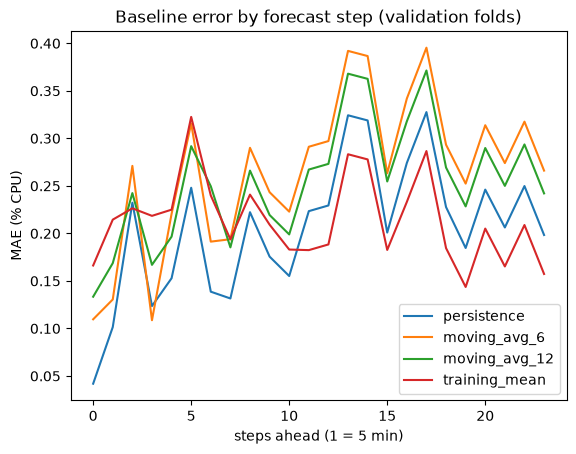

In [3]:
import matplotlib.pyplot as plt
target = "aggregate_cpu_utilization"
for name in ["persistence", "moving_avg_6", "moving_avg_12", "training_mean"]:
    pd.Series(abs(all_errors[(target, name)]).mean(axis=0)).plot(label=name)
plt.xlabel("steps ahead (1 = 5 min)"); plt.ylabel("MAE (% CPU)"); plt.legend()
plt.title("Baseline error by forecast step (validation folds)")
plt.savefig("../reports/figures/baseline_error_by_step.png", dpi=120, bbox_inches="tight")

In [10]:
table.round(4).to_csv("../reports/baseline_results.csv")

In [11]:
for name in ["persistence", "training_mean"]:
    folds, _ = evaluate_forecaster(train, baselines[name], "aggregate_cpu_utilization")
    print(name); print(folds.round(4))

persistence
   fold  n_train     mae    rmse
0     1       50  0.2681  0.3028
1     2       62  0.2975  0.3457
2     3       74  0.1245  0.1522
3     4       86  0.1324  0.1542
training_mean
   fold  n_train     mae    rmse
0     1       50  0.3026  0.3374
1     2       62  0.1727  0.2099
2     3       74  0.1707  0.1929
3     4       86  0.2105  0.2331


In [12]:
folds, errs = evaluate_forecaster(train, baselines["persistence"], "aggregate_cpu_utilization",
                                  min_train_size=30, step=6)   # gives 10 folds
print(len(folds), summarize(errs))

10 {'mae': 0.23843599318264228, 'rmse': 0.2880570021233115}


In [13]:
T = "aggregate_cpu_utilization"
peak_threshold = train[T].quantile(0.90)       # training window only (about 9.668)
for name in ["persistence", "training_mean"]:
    d = collect_predictions(train, baselines[name], T)
    d["is_peak"] = d["actual"] >= peak_threshold
    print(name,
          "| overall MAE", round(d["error"].abs().mean(), 4),
          "| peak MAE", round(d.loc[d.is_peak, "error"].abs().mean(), 4),
          "| non-peak MAE", round(d.loc[~d.is_peak, "error"].abs().mean(), 4),
          "| bias", round(d["error"].mean(), 4))

persistence | overall MAE 0.2056 | peak MAE 0.2953 | non-peak MAE 0.1877 | bias -0.0665
training_mean | overall MAE 0.2141 | peak MAE 0.4159 | non-peak MAE 0.1738 | bias -0.0048


In [15]:
rob = {}
for name, f in baselines.items():
    _, e = evaluate_forecaster(train, f, "aggregate_cpu_utilization",
                               min_train_size=30, step=6)
    rob[name] = summarize(e)
print(pd.DataFrame(rob).T.round(4).sort_values("mae"))

                      mae    rmse
training_mean      0.1949  0.2415
moving_avg_3       0.2226  0.2765
moving_avg_6       0.2255  0.2857
moving_avg_12      0.2368  0.2915
persistence        0.2384  0.2881
seasonal_naive_12  0.2455  0.3031
seasonal_naive_24  0.2734  0.3277
